# Fronteras en falla o hurto
## Descripción Base de Datos

Esta base de datos guarda la **publicación diaria de XM** con las fronteras comerciales vigentes en falla o hurto
(Resolución CREG 038 de 2014). Cada día es una foto: una falla aparece todos los días mientras siga abierta.

 **Estructura de los datos**:
   - Los datos son **estructurados** y están en tablas relacionadas en **Supabase (PostgreSQL)**, esquema `fronteras`.

 **Formato del archivo**:
   - XM publica un **Excel (.xlsx)** por día. El programa `pipeline/descargar.py` lo descarga y lo carga a la base.

 **Parser**:
   - No se lee el Excel aquí: se consulta la vista `fronteras.v_falla_publicada` con SQL, que ya trae todo unido.

 **Tipología de las variables**:
   - **Cualitativas nominales**: código SIC, tipo de frontera, equipo en falla, agentes y operador de red.
   - **Cuantitativas discretas**: días en falla.
   - **Temporales**: fecha de publicación, fecha de reporte y fecha máxima de normalización.

**Importante:** una fila no es una falla nueva, es una falla **observada ese día**. Por eso no se suman días para contar fallas.

## Librerias

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import psycopg

## Leer Datos
La conexión se lee de `pipeline/.env`. La contraseña no se escribe en el notebook.

In [2]:
# Leer la conexion a Supabase
archivo_env = Path("pipeline/.env").read_text(encoding="utf-8")
url = [l.split("=", 1)[1].strip() for l in archivo_env.splitlines() if l.startswith("DATABASE_URL=")][0]

def consulta(sql):
    with psycopg.connect(url, prepare_threshold=None) as con:
        cursor = con.execute(sql)
        columnas = [c.name for c in cursor.description]
        return pd.DataFrame(cursor.fetchall(), columns=columnas)

df = consulta("SELECT * FROM fronteras.v_falla_publicada")
df["fecha_publicacion"] = pd.to_datetime(df["fecha_publicacion"])
df["fecha_maxima_normalizacion"] = pd.to_datetime(df["fecha_maxima_normalizacion"])
df

,fecha_publicacion,codigo_sic,tipo_frontera,equipo_en_falla,categoria,fecha_reporte,fecha_maxima_normalizacion,dias_en_falla,solicito_ampliacion,fecha_solicitud_ampliacion,agente_reporta,agente_representante,operador_red
0,2026-10-18,Frt0107596,Tipo Consumo Propio,Falla Dispositivos de interfaz de comunicación,FALLA,2026-09-27 07:51:06,2026-10-27,21,Sí,2026-10-12,CARIBEMAR DE LA COSTA S.A.S. E.S.P. - DISTRIBU...,ERCO GENERACION S.A.S. ESP - GENERADOR,CARIBEMAR DE LA COSTA S.A.S. E.S.P. - DISTRIBU...
1,2026-10-18,Frt28374,Tipo Consumo Propio,Falla No Envío de Lectura,FALLA,2026-08-11 00:00:00,2026-08-26,68,No,None,PROYECTOS ENERGETICOS DEL CAUCA S.A. E.S.P. - ...,PROYECTOS ENERGETICOS DEL CAUCA S.A. E.S.P. - ...,COMPAÑIA ENERGETICA DE OCCIDENTE S.A.S. ESP - ...
2,2026-10-18,Frt45534,Tipo Consumo Propio,Falla No Envío de Lectura,FALLA,2026-04-10 00:00:00,2026-04-25,191,No,None,P.CH EL COCUYO SAS ESP - GENERADOR,P.CH EL COCUYO SAS ESP - GENERADOR,EMPRESAS PUBLICAS DE MEDELLIN E.S.P. - DISTRIB...
3,2026-10-18,Frt75759,Tipo Consumo Propio,Falla Dispositivos de interfaz de comunicación,FALLA,2026-10-12 14:59:57,2026-10-27,6,No,None,VATIA S.A. E.S.P. - GENERADOR,VATIA S.A. E.S.P. - GENERADOR,CARIBEMAR DE LA COSTA S.A.S. E.S.P. - DISTRIBU...
4,2026-10-18,Frt76577,Tipo Consumo Propio,Falla Dispositivos de interfaz de comunicación,FALLA,2026-10-09 13:38:47,2026-10-24,9,No,None,DEPI ENERGY S.A.S. E.S.P. - GENERADOR,DEPI ENERGY S.A.S. E.S.P. - GENERADOR,CARIBEMAR DE LA COSTA S.A.S. E.S.P. - DISTRIBU...
...,...,...,...,...,...,...,...,...,...,...,...,...,...
59119,2026-10-30,Frt82058,Tipo Regulado,Falla Dispositivos de interfaz de comunicación,FALLA,2026-10-29 17:41:03,2026-11-13,1,No,None,BIA ENERGY S.A.S. E.S.P - COMERCIALIZADOR,BIA ENERGY S.A.S. E.S.P - COMERCIALIZADOR,EMPRESA DE ENERGIA DE PEREIRA S.A. E.S.P. - DI...
59120,2026-10-30,Frt33329,Tipo Regulado,Falla Dispositivos de interfaz de comunicación,FALLA,2026-10-16 17:18:49,2026-10-31,14,No,None,VATIA S.A. E.S.P. - COMERCIALIZADOR,VATIA S.A. E.S.P. - COMERCIALIZADOR,EMPRESA DE ENERGIA DE PEREIRA S.A. E.S.P. - DI...
59121,2026-10-30,Frt60690,Tipo Regulado,Falla Transformador de Corriente (TC),FALLA,2026-10-09 15:30:30,2026-11-08,21,No,None,VATIA S.A. E.S.P. - COMERCIALIZADOR,VATIA S.A. E.S.P. - COMERCIALIZADOR,EMPRESA DE ENERGIA DE PEREIRA S.A. E.S.P. - DI...
59122,2026-10-30,Frt30186,Tipo No Regulado,Falla Transformador de Corriente (TC),FALLA,2026-10-19 18:24:56,2026-11-18,11,No,None,EMPRESA DE ENERGIA DE PEREIRA S.A. E.S.P. - CO...,EMPRESA DE ENERGIA DE PEREIRA S.A. E.S.P. - CO...,EMPRESA DE ENERGIA DE PEREIRA S.A. E.S.P. - DI...


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 59124 entries, 0 to 59123
Data columns (total 13 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   fecha_publicacion           59124 non-null  datetime64[s] 
 1   codigo_sic                  59124 non-null  str           
 2   tipo_frontera               59124 non-null  str           
 3   equipo_en_falla             59124 non-null  str           
 4   categoria                   59124 non-null  str           
 5   fecha_reporte               59124 non-null  datetime64[us]
 6   fecha_maxima_normalizacion  59124 non-null  datetime64[s] 
 7   dias_en_falla               59124 non-null  int64         
 8   solicito_ampliacion         59124 non-null  str           
 9   fecha_solicitud_ampliacion  28594 non-null  object        
 10  agente_reporta              59124 non-null  str           
 11  agente_representante        59124 non-null  str           
 12  o

In [4]:
# Colores y estilo de todas las graficas
azul, naranja, gris = "#2a78d6", "#eb6834", "#b8b7b0"
sns.set(style="whitegrid")

# Foto del ultimo dia publicado
ultimo = df["fecha_publicacion"].max()
hoy = df[df["fecha_publicacion"] == ultimo].copy()
print("Periodo:", df["fecha_publicacion"].min().date(), "a", ultimo.date())
print("Fallas activas el ultimo dia:", len(hoy), "| fronteras:", hoy["codigo_sic"].nunique())

Periodo: 2026-10-01 a 2026-11-06
Fallas activas el ultimo dia: 1741 | fronteras: 1702


# EDA

## Fallas activas por día

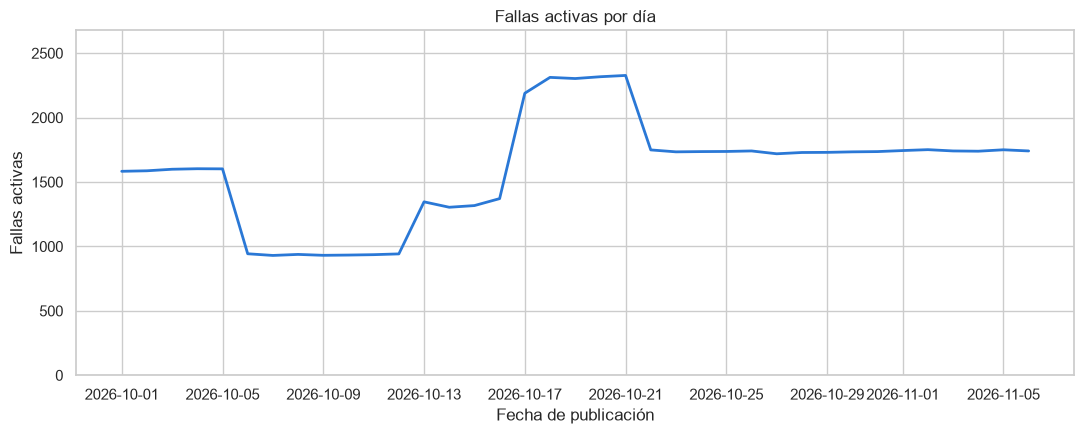

In [5]:
activas = df.groupby("fecha_publicacion").size()

plt.figure(figsize=(11, 4.5))
plt.plot(activas.index, activas.values, color=azul, linewidth=2)
plt.ylim(0, activas.max() * 1.15)
plt.xlabel("Fecha de publicación")
plt.ylabel("Fallas activas")
plt.title("Fallas activas por día")
plt.tight_layout()
plt.show()

La serie no se mueve poco a poco: da **saltos de cientos de fallas en un solo día**. Bajó de 1.602 a 943 el 6 de octubre,
subió a 2.189 el 17 y volvió a 1.749 el 22. Desde entonces está estable alrededor de 1.740.

## Entradas y salidas por día

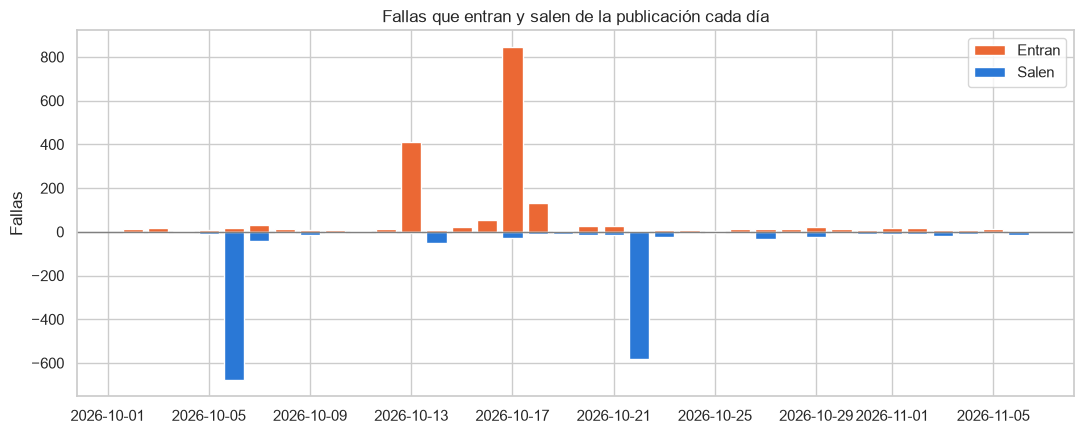

,Entran,Salen
2026-10-17,845,27
2026-10-13,410,6
2026-10-18,131,8
2026-10-16,56,2
2026-10-07,30,42


In [6]:
# Una falla entra el primer dia que aparece y sale el dia siguiente al ultimo
df["evento"] = df["codigo_sic"] + "|" + df["equipo_en_falla"] + "|" + df["fecha_reporte"].astype(str)
vida = df.groupby("evento")["fecha_publicacion"].agg(["min", "max"])

entradas = vida["min"].value_counts().sort_index()
salidas = (vida["max"] + pd.Timedelta(days=1)).value_counts().sort_index()
primero = df["fecha_publicacion"].min()
entradas = entradas[entradas.index > primero]
salidas = salidas[salidas.index <= ultimo]

plt.figure(figsize=(11, 4.5))
plt.bar(entradas.index, entradas.values, color=naranja, label="Entran")
plt.bar(salidas.index, -salidas.values, color=azul, label="Salen")
plt.axhline(0, color="gray", linewidth=1)
plt.ylabel("Fallas")
plt.title("Fallas que entran y salen de la publicación cada día")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

pd.DataFrame({"Entran": entradas, "Salen": salidas}).fillna(0).astype(int).sort_values("Entran", ascending=False).head(5)

Casi todo el movimiento ocurre en **pocos días**. Un día normal entran y salen unas decenas de fallas; en los días de salto, cientos.
Eso apunta a **eventos masivos**, no a daños individuales de equipos.

## Tipo de falla el último día

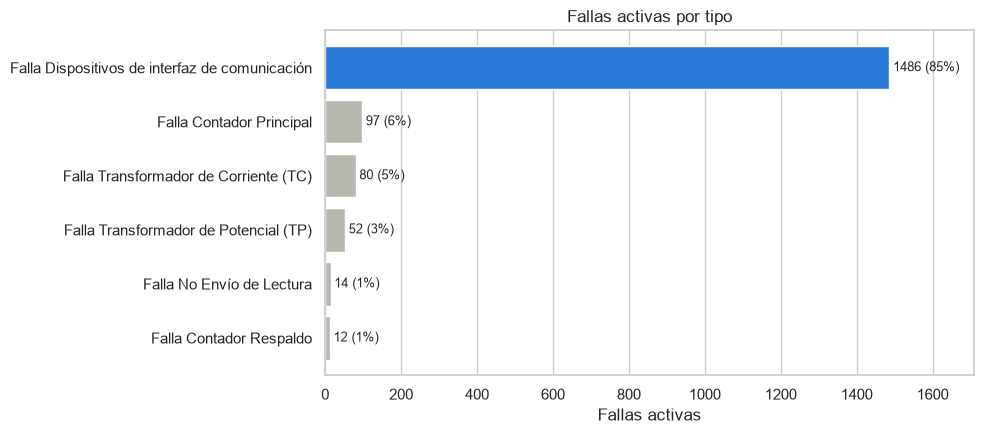

In [7]:
tipos = hoy["equipo_en_falla"].value_counts().sort_values()

plt.figure(figsize=(10, 4.5))
colores = [azul if "comunicación" in t else gris for t in tipos.index]
plt.barh(tipos.index, tipos.values, color=colores)
for i, v in enumerate(tipos.values):
    plt.text(v + 10, i, f"{v} ({v / len(hoy):.0%})", va="center", fontsize=9)
plt.xlim(0, tipos.max() * 1.15)
plt.xlabel("Fallas activas")
plt.title("Fallas activas por tipo")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

Las fallas de **dispositivos de interfaz de comunicación** son el **85%** de lo activo. Los equipos que miden
(contador y transformadores) suman menos del 14%.

## Concentración por representante

Mayor representante: Representante A | 81.4% de lo activo
Representantes con fallas activas: 39


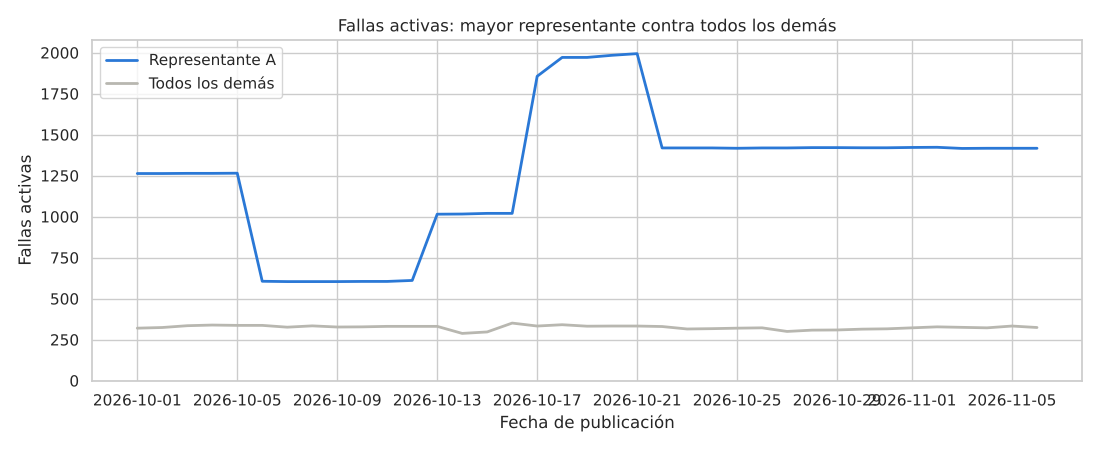

In [8]:
representantes = hoy["agente_representante"].value_counts()
mayor = representantes.index[0]
# El nombre del representante se anonimiza para la publicación
nombres = {mayor: "Representante A"}
print("Mayor representante:", nombres[mayor], "|", f"{representantes.iloc[0] / len(hoy):.1%} de lo activo")
print("Representantes con fallas activas:", len(representantes))

# Serie diaria: el mayor representante contra todos los demas
serie = df.assign(grupo=np.where(df["agente_representante"] == mayor, nombres[mayor], "Todos los demás"))
serie = serie.groupby(["fecha_publicacion", "grupo"]).size().unstack(fill_value=0)

plt.figure(figsize=(11, 4.5))
plt.plot(serie.index, serie[nombres[mayor]], color=azul, linewidth=2, label=nombres[mayor])
plt.plot(serie.index, serie["Todos los demás"], color=gris, linewidth=2, label="Todos los demás")
plt.ylim(0, None)
plt.xlabel("Fecha de publicación")
plt.ylabel("Fallas activas")
plt.title("Fallas activas: mayor representante contra todos los demás")
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

Este es el hallazgo principal: **un solo representante tiene el 81% de las fallas activas**, y los saltos de la serie son suyos.
El resto del sistema casi no se mueve. Los datos muestran el patrón, pero **no su causa**: no se puede decir si es una falla del
servicio de comunicaciones, una forma de reportar por lotes u otra razón. Hay que preguntarlo antes de concluir.

## Fallas por operador de red

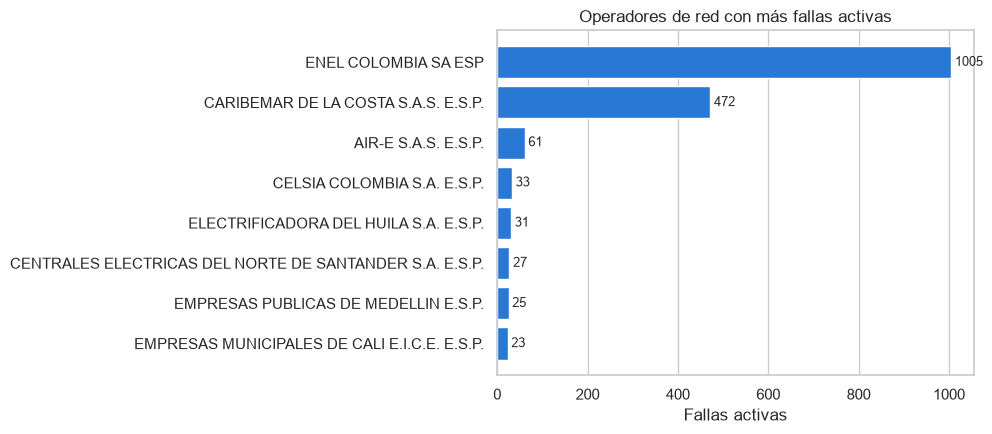

In [9]:
operadores = hoy["operador_red"].str.rsplit(" - ", n=1).str[0].value_counts().head(8).sort_values()

plt.figure(figsize=(10, 4.5))
plt.barh(operadores.index, operadores.values, color=azul)
for i, v in enumerate(operadores.values):
    plt.text(v + 8, i, v, va="center", fontsize=9)
plt.xlabel("Fallas activas")
plt.title("Operadores de red con más fallas activas")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

Dos operadores de red concentran **más de cuatro de cada cinco** fallas activas. Conviene cruzar este dato con el del representante,
porque puede ser el mismo grupo de fronteras visto desde otro ángulo.

## Antigüedad de las fallas

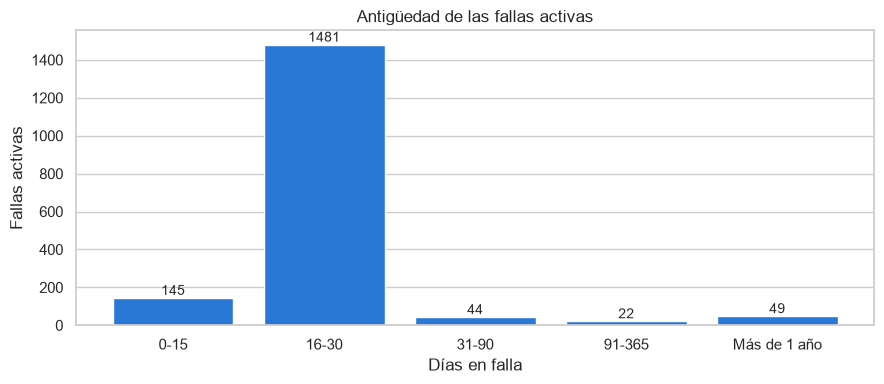

Mediana: 21.0 días | Máximo: 1059 días


In [10]:
bandas = pd.cut(hoy["dias_en_falla"], bins=[-1, 15, 30, 90, 365, 100000],
                labels=["0-15", "16-30", "31-90", "91-365", "Más de 1 año"])
conteo = bandas.value_counts().sort_index()

plt.figure(figsize=(9, 4))
plt.bar(conteo.index.astype(str), conteo.values, color=azul)
for i, v in enumerate(conteo.values):
    plt.text(i, v + 15, v, ha="center", fontsize=10)
plt.xlabel("Días en falla")
plt.ylabel("Fallas activas")
plt.title("Antigüedad de las fallas activas")
plt.grid(axis="x")
plt.tight_layout()
plt.show()

print("Mediana:", hoy["dias_en_falla"].median(), "días | Máximo:", hoy["dias_en_falla"].max(), "días")

La mayoría lleva **entre 16 y 30 días**, con mediana de 21. Eso coincide con el último evento masivo, así que no refleja un
tiempo normal de reparación. Aparte quedan **49 fallas con más de un año**, que son el verdadero rezago.

## Plazos vencidos y ampliaciones

In [11]:
hoy["vencida"] = hoy["fecha_maxima_normalizacion"] < hoy["fecha_publicacion"]
print("Plazo vencido:", hoy["vencida"].sum(), f"({hoy['vencida'].mean():.1%})")
print("Con ampliación:", f"{(hoy['solicito_ampliacion'] == 'Sí').mean():.1%}")

resumen = hoy.groupby("equipo_en_falla").agg(Activas=("vencida", "size"), Vencidas=("vencida", "sum"))
resumen["% vencidas"] = (resumen["Vencidas"] / resumen["Activas"] * 100).round(1)
resumen.sort_values("% vencidas", ascending=False)

Plazo vencido: 79 (4.5%)
Con ampliación: 87.2%


,Activas,Vencidas,% vencidas
equipo_en_falla,,,
Falla Contador Respaldo,12,10,83.3
Falla No Envío de Lectura,14,8,57.1
Falla Transformador de Potencial (TP),52,23,44.2
Falla Transformador de Corriente (TC),80,18,22.5
Falla Contador Principal,97,11,11.3
Falla Dispositivos de interfaz de comunicación,1486,9,0.6


Solo el **4,5%** de lo activo tiene el plazo vencido, pero el **87%** solicitó ampliación. El vencimiento pesa mucho más en los
transformadores y contadores que en comunicación, aunque estos son pocos. El Anexo 7 de la CREG 038 de 2014 da 15 días para
comunicación y contadores y 30 para transformadores, ampliables una vez.

## Conclusiones
Corte: 6 de noviembre de 2026, con **37 días** de datos.

### Comunicación
- El 85% de las fallas activas son de comunicación. El problema no es que el equipo mida mal, sino que el dato no llega.

### Concentración
- Un solo representante tiene el 81% de lo activo y explica los saltos de octubre. Dos operadores de red concentran más del 80%.

### Rezago
- 49 fallas superan un año y 79 tienen el plazo vencido. Son pocas, pero son las que más riesgo de cancelación tienen.

## Recomendaciones

- **Averiguar la causa de los saltos**: confirmar con el representante o con XM qué pasó el 6, 17 y 22 de octubre.
- **Medir sin ese efecto**: seguir la serie con y sin el mayor representante para ver la tendencia real.
- **Priorizar el rezago**: revisar primero las fallas de más de un año y las de plazo vencido.
- **Ampliar el histórico**: con 37 días no se pueden sacar conclusiones de estacionalidad. El dato irá creciendo con la carga diaria.